# Entrenamiento del detector YOLO11n

Este notebook implementa el entrenamiento y la evaluación de YOLO11n para localizar eventos acústicos de aves en espectrogramas.

El modelo se inicializará con pesos preentrenados en COCO y se adaptará a una única clase: `BIRD_EVENT`.

Se utilizarán los mismos datos, particiones por grabación y criterios de evaluación definidos para Faster R-CNN, con el propósito de comparar ambas arquitecturas bajo condiciones experimentales equivalentes, el procedimiento comprende preparación de datos, búsqueda de hiperparámetros, entrenamiento definitivo y evaluación.


## Preparación del entorno

In [ ]:
%pip -q install "ultralytics==8.4.207" "kagglehub>=1.0.3" "kaggle>=1.7"

from pathlib import Path
import gc
import json
import random
import re
import shutil
import zipfile
import numpy as np
import pandas as pd
import torch
import yaml
import kagglehub
import ultralytics
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset
import os
import hashlib
import time
from google.colab import userdata
import subprocess
import matplotlib.pyplot as plt
from ultralytics.models.yolo.detect.train import DetectionTrainer
from ultralytics.engine.trainer import BaseTrainer
import math


SEED = 0
BATCH_INICIAL = 8
IMGSZ = 640
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("KaggleHub:", kagglehub.__version__)
print("GPU disponible:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cu130
Ultralytics: 8.4.207
KaggleHub: 1.0.3
GPU disponible: True


Para este experimento se probará un ``batch_size=8``, superior a Faster R-CNN

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

BASE_LOCAL = Path("/content/proyecto_aves")
BASE_DRIVE = Path("/content/drive/MyDrive/Proyecto_Aves")
DIR_E2 = BASE_DRIVE / "experiments/detector/E2_YOLO11n"
BASE_LOCAL.mkdir(parents=True, exist_ok=True)
DIR_E2.mkdir(parents=True, exist_ok=True)

print("Datos temporales:", BASE_LOCAL)
print("Experimento E2:", DIR_E2)

Mounted at /content/drive
Datos temporales: /content/proyecto_aves
Experimento E2: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E2_YOLO11n


## Recuperacion del dataset HPO

Se recupera el subconjunto de HPO publicado en Kaggle, compuesto por 8.000 espectrogramas de entrenamiento y 2.000 de validacion, los archivos se almacenan temporalmente en Colab y se reutilizan durante los ensayos, nmo se requiere reconstruir los espectrogramas ni descargar los audios FLAC originales


In [ ]:
DATASET_HPO = "santiagocorrea802/yolo11n-hpo-espectrogramas-de-aves"
RUTA_HPO_LOCAL = BASE_LOCAL / "yolo11n" / "hpo"
RUTA_HPO_LOCAL.mkdir(parents=True, exist_ok=True)

def encontrar_raiz(ruta):
    if (ruta / "images/train").is_dir() and (ruta / "labels/val").is_dir():
        return ruta
    return next((p.parent.parent for p in ruta.rglob("images/train") if (p.parent.parent / "labels/val").is_dir()), None)

RAIZ_HPO = encontrar_raiz(RUTA_HPO_LOCAL)

if RAIZ_HPO is None:
    origen = Path(kagglehub.dataset_download(DATASET_HPO))

    RAIZ_HPO = encontrar_raiz(origen)

    if RAIZ_HPO is None:
        archivos_zip = list(origen.rglob("hpo_yolo11n.zip"))
        if len(archivos_zip) != 1:
            raise FileNotFoundError("No se encontro el paquete HPO")

        with zipfile.ZipFile(archivos_zip[0]) as z:
            if any(Path(f.filename).is_absolute() or ".." in Path(f.filename).parts for f in z.infolist()):
                raise ValueError("El ZIP contiene rutas invalidas")
            z.extractall(RUTA_HPO_LOCAL)

        RAIZ_HPO = encontrar_raiz(RUTA_HPO_LOCAL)

if RAIZ_HPO is None:
    raise FileNotFoundError("No se encontro la estructura images/labels del dataset HPO")

print("Dataset HPO:", RAIZ_HPO)

Using Colab cache for faster access to the 'yolo11n-hpo-espectrogramas-de-aves' dataset.
Dataset HPO: /kaggle/input/yolo11n-hpo-espectrogramas-de-aves/hpo_yolo11n


### Validacion y configuracion para Ultralytics

Se comprueba la cantidad de imagenes, la correspondencia con sus etiquetas y la seleccion original de ventanas, se generan las listas `train.txt` y `val.txt` junto con `dataset.yaml`, necesarios para entrenar YOLO11n mediante Ultralytics.


In [ ]:
seleccion_hpo = pd.read_csv(RAIZ_HPO.parent / "seleccion_hpo.csv")
conteos = seleccion_hpo["split"].value_counts()

if conteos.get("train", 0) != 8000 or conteos.get("validation", 0) != 2000:
    raise ValueError("El manifiesto HPO tiene cantidades incorrectas")

rutas_hpo = {}

for particion, cantidad in [("train", 8000), ("val", 2000)]:
    imagenes = sorted((RAIZ_HPO / "images" / particion).glob("*.png"))
    etiquetas = list((RAIZ_HPO / "labels" / particion).glob("*.txt"))

    if len(imagenes) != cantidad or {p.stem for p in imagenes} != {p.stem for p in etiquetas}:
        raise ValueError(f"Imagenes o etiquetas incompletas: {particion}")

    rutas_hpo[particion] = imagenes
    (RUTA_HPO_LOCAL / f"{particion}.txt").write_text("\n".join(map(str, imagenes)) + "\n", encoding="utf-8")

configuracion = {
    "path": str(RUTA_HPO_LOCAL.resolve()),
    "train": "train.txt",
    "val": "val.txt",
    "names": {0: "BIRD_EVENT"}
}

RUTA_YAML_ENTRENAMIENTO = RUTA_HPO_LOCAL / "dataset.yaml"
RUTA_YAML_ENTRENAMIENTO.write_text(yaml.safe_dump(configuracion, sort_keys=False), encoding="utf-8")

datos = check_det_dataset(str(RUTA_YAML_ENTRENAMIENTO))

assert datos["names"][0] == "BIRD_EVENT"
assert len(rutas_hpo["train"]) == 8000
assert len(rutas_hpo["val"]) == 2000

print("Dataset HPO validado")
print("Train:", len(rutas_hpo["train"]))
print("Validation:", len(rutas_hpo["val"]))
print("YAML:", RUTA_YAML_ENTRENAMIENTO)

## Busqueda de hiperparametros de YOLO11n

Se evaluaran seis configuraciones de YOLO11n inicializadas con pesos preentrenados en COCO, los ensayos utilizaran un subconjunto fijo de 8.000 ventanas de entrenamiento y 2.000 de validacion, se exploraran principalmente la tasa de aprendizaje, el tamaño de batch y la regularizacion

La seleccion se realizara mediante AP50 sobre validacion. Los resultados se almacenaran en Google Drive, mientras los pesos y archivos auxiliares de cada ensayo permaneceran temporalmente en Colab, antes de ejecutar la busqueda completa, se realizara una prueba de funcionamiento para verificar el entrenamiento, la validacion y el consumo de GPU.


**Configuracion de HPO y persistencia**

Esta celda registra el subconjunto utilizado y prepara la carpeta de resultados

In [ ]:
DIR_HPO = DIR_E2 / "hpo_v1"
DIR_HPO_LOCAL = BASE_LOCAL / "yolo11n" / "hpo_runs"
DIR_HPO.mkdir(parents=True, exist_ok=True)
DIR_HPO_LOCAL.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError("Se necesita una GPU para ejecutar HPO")

columnas = ["recording_uid", "ventana_id", "split", "archivo", "parte"]
seleccion_actual = seleccion_hpo[columnas].sort_values(columnas).reset_index(drop=True)
ruta_seleccion = DIR_HPO / "seleccion_hpo.csv.gz"

if ruta_seleccion.exists():
    seleccion_guardada = pd.read_csv(ruta_seleccion).sort_values(columnas).reset_index(drop=True)
    pd.testing.assert_frame_equal(seleccion_actual, seleccion_guardada, check_dtype=False)
else:
    seleccion_actual.to_csv(ruta_seleccion, index=False, compression="gzip")

print("GPU:", torch.cuda.get_device_name(0))
print("VRAM (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
print("Train:", len(rutas_hpo["train"]))
print("Validation:", len(rutas_hpo["val"]))
print("Resultados:", DIR_HPO)

**Prueba del entrenador de Ultralytics**

Antes de ejecutar seis ensayos completos, probaremos un entrenamiento de una época sobre 64 imágenes train y 32 validation, esta prueba no forma parte de la HPO,unicamente verifica que Ultralytics puede consumir correctamente los espectrogramas y sus etiquetas.

In [ ]:
RUTA_SMOKE = RUTA_HPO_LOCAL / "smoke"
RUTA_SMOKE.mkdir(parents=True, exist_ok=True)

for particion, cantidad in [("train", 64), ("val", 32)]:
    rutas = rutas_hpo[particion][:cantidad]
    (RUTA_SMOKE / f"{particion}.txt").write_text("\n".join(map(str, rutas)) + "\n", encoding="utf-8")

config_smoke = {
    "path": str(RUTA_SMOKE.resolve()),
    "train": "train.txt",
    "val": "val.txt",
    "names": {0: "BIRD_EVENT"}
}

RUTA_SMOKE_YAML = RUTA_SMOKE / "dataset.yaml"
RUTA_SMOKE_YAML.write_text(yaml.safe_dump(config_smoke, sort_keys=False), encoding="utf-8")
modelo = YOLO("yolo11n.pt")
metricas = modelo.train(
    data=str(RUTA_SMOKE_YAML), epochs=1, imgsz=640, batch=8, device=0,
    optimizer="AdamW", lr0=0.001, weight_decay=0.0005, nbs=64,
    seed=SEED, deterministic=True, amp=True, workers=2, cache=False,
    mosaic=0, mixup=0, copy_paste=0, fliplr=0, flipud=0,
    degrees=0, translate=0, scale=0, shear=0, perspective=0,
    hsv_h=0, hsv_s=0, hsv_v=0, bgr=0,
    project=str(DIR_HPO_LOCAL), name="smoke", exist_ok=True,
    save=True, plots=False, val=True, verbose=False
)

if metricas is None or not np.isfinite(metricas.box.map50):
    raise RuntimeError("No se obtuvieron metricas validas")

resultado_smoke = {
    "ap50": float(metricas.box.map50),
    "train_images": 64,
    "val_images": 32,
    "ultralytics": ultralytics.__version__,
    "torch": torch.__version__
}

(DIR_HPO / "smoke.json").write_text(json.dumps(resultado_smoke, indent=2), encoding="utf-8")
print("Prueba completada")
print("AP50 de prueba:", round(resultado_smoke["ap50"], 4))
print("VRAM reservada (GiB):", round(torch.cuda.max_memory_reserved() / 1024**3, 2))

del modelo, metricas
gc.collect()
torch.cuda.empty_cache()
shutil.rmtree(DIR_HPO_LOCAL / "smoke", ignore_errors=True)

### Configuracion de los ensayos HPO

Se evaluaran seis configuraciones de YOLO11n sobre las mismas 8.000 ventanas de entrenamiento y 2.000 de validacion, los ensayos partiran de los pesos preentrenados `yolo11n.pt`. Se mantendran constantes la resolucion, el optimizador, la semilla y el presupuesto de epocas.

La seleccion se realizara mediante AP50. Los resultados y un checkpoint temporal de recuperacion se almacenaran en Drive para permitir reanudar ensayos interrumpidos.


In [ ]:
EPOCAS_HPO = 12
RUTA_RESULTADOS = DIR_HPO / "resultados.csv"
DIR_ACTIVO = DIR_HPO / "activo"

CONFIGS_HPO = [
    {"ensayo": 1, "lr0": 0.001, "weight_decay": 0.0005, "batch": 8},
    {"ensayo": 2, "lr0": 0.0003, "weight_decay": 0.0005, "batch": 8},
    {"ensayo": 3, "lr0": 0.003, "weight_decay": 0.0005, "batch": 8},
    {"ensayo": 4, "lr0": 0.001, "weight_decay": 0.0001, "batch": 8},
    {"ensayo": 5, "lr0": 0.001, "weight_decay": 0.0005, "batch": 4},
    {"ensayo": 6, "lr0": 0.001, "weight_decay": 0.0005, "batch": 16}
]

config_hpo = {
    "modelo": "yolo11n.pt",
    "ultralytics": ultralytics.__version__,
    "dataset": DATASET_HPO,
    "epocas": EPOCAS_HPO,
    "imgsz": IMGSZ,
    "nbs": 64,
    "seed": SEED,
    "ensayos": CONFIGS_HPO
}

ruta_configs = DIR_HPO / "configuraciones.json"

if ruta_configs.exists():
    if json.loads(ruta_configs.read_text()) != config_hpo:
        raise RuntimeError("La configuracion HPO difiere de la guardada en Drive")
else:
    ruta_configs.write_text(json.dumps(config_hpo, indent=2), encoding="utf-8")

print("Ensayos:", len(CONFIGS_HPO))
print("Epocas por ensayo:", EPOCAS_HPO)
print("Directorio:", DIR_HPO)

In [ ]:
import json

guardada = json.loads(
    (DIR_HPO / "configuraciones.json").read_text(encoding="utf-8")
)

print("COMPARACIÓN DE CONFIGURACIONES\n")

diferencias = 0

for clave in sorted(set(guardada) | set(config_hpo)):
    anterior = guardada.get(clave, "<ausente>")
    actual = config_hpo.get(clave, "<ausente>")

    if anterior != actual:
        diferencias += 1
        print(f"CAMPO DIFERENTE: {clave}")
        print(f"  Ayer: {anterior}")
        print(f"  Hoy:  {actual}")
        print()

print("Total de diferencias:", diferencias)

In [ ]:
def ejecutar_ensayo(cfg):
    numero = cfg["ensayo"]
    nombre = f"ensayo_{numero:02d}"
    resultados = pd.read_csv(RUTA_RESULTADOS) if RUTA_RESULTADOS.exists() else pd.DataFrame()

    if not resultados.empty and numero in resultados["ensayo"].values:
        print(f"{nombre}: completado anteriormente")
        return

    ruta_estado = DIR_ACTIVO / "estado.json"
    estado = json.loads(ruta_estado.read_text()) if ruta_estado.exists() else None
    if estado and estado["ensayo"] != numero:
        raise RuntimeError(f"Hay un ensayo pendiente: {estado['ensayo']}")

    DIR_ACTIVO.mkdir(parents=True, exist_ok=True)
    if estado is None:
        estado = {"ensayo": numero, "epoca": 0, "ap50_max": -1.0, "epoca_mejor": 0}

    def guardar_checkpoint(trainer):
        ap50 = float(trainer.metrics["metrics/mAP50(B)"])
        origen = Path(trainer.last)
        destino = DIR_ACTIVO / "last.pt"
        temporal = DIR_ACTIVO / "last.pt.tmp"
        shutil.copy2(origen, temporal)
        os.replace(temporal, destino)

        if np.isfinite(ap50) and ap50 > estado["ap50_max"]:
            temporal = DIR_ACTIVO / "mejor_ap50.pt.tmp"
            shutil.copy2(origen, temporal)
            os.replace(temporal, DIR_ACTIVO / "mejor_ap50.pt")
            estado["ap50_max"] = ap50
            estado["epoca_mejor"] = trainer.epoch + 1

        estado["epoca"] = trainer.epoch + 1
        temporal = DIR_ACTIVO / "estado.json.tmp"
        temporal.write_text(json.dumps(estado), encoding="utf-8")
        os.replace(temporal, ruta_estado)

        historial = Path(trainer.save_dir) / "results.csv"
        if historial.is_file():
            shutil.copy2(historial, DIR_HPO / f"historial_{nombre}.csv")

    inicio = time.perf_counter()

    if estado["epoca"] < EPOCAS_HPO:
        reanudar = estado["epoca"] > 0 and (DIR_ACTIVO / "last.pt").is_file()
        modelo = YOLO(str(DIR_ACTIVO / "last.pt") if reanudar else "yolo11n.pt")
        modelo.add_callback("on_model_save", guardar_checkpoint)
        argumentos = {
            "data": str(RUTA_YAML_ENTRENAMIENTO),
            "device": 0,
            "workers": 2,
            "project": str(DIR_HPO_LOCAL),
            "name": nombre,
            "exist_ok": True,
            "plots": False,
            "verbose": False
        }

        if reanudar:
            modelo.train(resume=True, **argumentos)
        else:
            modelo.train(
                epochs=EPOCAS_HPO, imgsz=IMGSZ, batch=cfg["batch"],
                optimizer="AdamW", lr0=cfg["lr0"], weight_decay=cfg["weight_decay"],
                nbs=64, seed=SEED, deterministic=True, amp=True,
                warmup_epochs=1, patience=100, cache=False,
                mosaic=0, mixup=0, copy_paste=0, fliplr=0, flipud=0,
                degrees=0, translate=0, scale=0, shear=0, perspective=0,
                hsv_h=0, hsv_s=0, hsv_v=0, bgr=0,
                close_mosaic=0, save=True, save_period=-1, **argumentos
            )

        del modelo
        gc.collect()
        torch.cuda.empty_cache()

    mejor = DIR_ACTIVO / "mejor_ap50.pt"
    if not mejor.is_file():
        raise FileNotFoundError("No se encontro el mejor checkpoint del ensayo")

    modelo = YOLO(str(mejor))
    metricas = modelo.val(
        data=str(RUTA_YAML_ENTRENAMIENTO), split="val",
        imgsz=IMGSZ, batch=8, device=0, workers=2,
        plots=False, verbose=False, project=str(DIR_HPO_LOCAL),
        name=f"validacion_{numero:02d}", exist_ok=True
    )

    fila = {
        **cfg,
        "epocas": estado["epoca"],
        "epoca_mejor": estado["epoca_mejor"],
        "ap50": float(metricas.box.map50),
        "map50_95": float(metricas.box.map),
        "precision": float(metricas.box.mp),
        "recall": float(metricas.box.mr),
        "tiempo_s_sesion": round(time.perf_counter() - inicio, 1)
    }

    if not all(np.isfinite(fila[k]) for k in ("ap50", "map50_95", "precision", "recall")):
        raise RuntimeError(f"Metricas invalidas: {nombre}")

    resultados = pd.concat([resultados, pd.DataFrame([fila])], ignore_index=True)
    resultados = resultados.sort_values("ensayo")
    temporal = RUTA_RESULTADOS.with_suffix(".csv.tmp")
    resultados.to_csv(temporal, index=False)
    os.replace(temporal, RUTA_RESULTADOS)

    ganador = resultados.sort_values("ap50", ascending=False).iloc[0]
    mejor_config = next(c for c in CONFIGS_HPO if c["ensayo"] == int(ganador["ensayo"]))
    (DIR_HPO / "mejor_config.json").write_text(json.dumps(mejor_config, indent=2), encoding="utf-8")

    print(f"{nombre}: AP50={fila['ap50']:.4f} | mAP50-95={fila['map50_95']:.4f}")
    print("Resultados guardados en Drive")

    del modelo, metricas
    gc.collect()
    torch.cuda.empty_cache()
    shutil.rmtree(DIR_ACTIVO)
    shutil.rmtree(DIR_HPO_LOCAL / nombre, ignore_errors=True)
    shutil.rmtree(DIR_HPO_LOCAL / f"validacion_{numero:02d}", ignore_errors=True)

**EJECUTAR ENSAYOS**

In [ ]:
for cfg in CONFIGS_HPO:
    ejecutar_ensayo(cfg)

print("\nResumen HPO:")
display(pd.read_csv(RUTA_RESULTADOS).sort_values("ap50", ascending=False))

In [ ]:
seleccion_hpo = pd.read_csv(RAIZ_HPO.parent / "seleccion_hpo.csv")

### Resultados de la búsqueda de hiperparámetros

Se completaron seis ensayos de optimización de hiperparámetros para YOLO11n, utilizando 8.000 espectrogramas de entrenamiento y 2.000 de validación, cada configuración se entrenó durante 12 épocas, manteniendo constantes la arquitectura, la resolución de entrada y el procedimiento de evaluación

El **ensayo 04** obtuvo el mayor AP50 (0.1510) y mAP50-95 (0.0544), con una tasa de aprendizaje de 0.001, regularización `weight_decay=0.0001` y tamaño de lote de 8 imágenes. Sin embargo, el mejor rendimiento se alcanzó en la época 5, observándose posteriormente una disminución de las métricas de validación

Debido al rendimiento limitado, se realizaron verificaciones adicionales de las anotaciones y una prueba de memorización con 32 espectrogramas. Esta última alcanzó un AP50 de 0.9431 y un mAP50-95 de 0.8913, evaluando sobre las mismas imágenes utilizadas para entrenar. El resultado demuestra que YOLO11n puede ajustarse a un subconjunto pequeño, pero no constituye una medida de generalización.

Se selecciona la configuración del ensayo 04 como punto de partida para el entrenamiento definitivo. Se utilizarán los pesos preentrenados originales de YOLO11n, un presupuesto de épocas mayor, parada anticipada y conservación de checkpoints. El rendimiento definitivo deberá evaluarse sobre un conjunto de prueba independiente

## Preparar el entrenamiento definitivo

**Preparación del dataset completo desde Kaggle**

In [ ]:
from ultralytics.data.utils import img2label_paths

NOTEBOOK_KAGGLE = "santiagocorrea802/notebook1240c3d28f/versions/1"
RAIZ_FINAL = BASE_LOCAL / "yolo11n" / "dataset_final"
DIR_FINAL = DIR_E2 / "final_v1"

RAIZ_FINAL.mkdir(parents=True, exist_ok=True)
DIR_FINAL.mkdir(parents=True, exist_ok=True)

print("Espacio libre antes de la descarga:",
      round(shutil.disk_usage("/content").free / 1024**3, 2), "GiB")

NOTEBOOK_KAGGLE = "santiagocorrea802/notebook1240c3d28f"

destino = RAIZ_FINAL / "kaggle"
carpeta_zips = RAIZ_FINAL / "zips"

destino.mkdir(parents=True, exist_ok=True)
carpeta_zips.mkdir(parents=True, exist_ok=True)

for i in range(1, 17):
    parte = f"yolo11n_completo_parte_{i:02d}"
    carpeta = destino / parte
    esperado = 3000 if i < 16 else 1255

    if len(list(carpeta.rglob("*.png"))) == esperado and \
       len(list(carpeta.rglob("*.txt"))) == esperado:
        print(f"Parte {i:02d}/16 ya disponible")
        continue

    nombre_zip = f"{parte}.zip"
    archivo = carpeta_zips / nombre_zip

    if not archivo.is_file():
        archivo = Path(kagglehub.notebook_output_download(
            NOTEBOOK_KAGGLE,
            path=nombre_zip,
            output_dir=str(carpeta_zips)
        ))

    with zipfile.ZipFile(archivo) as z:
        nombres = [
            Path(info.filename)
            for info in z.infolist()
            if not info.is_dir()
        ]

        if not nombres or any(
            p.is_absolute() or ".." in p.parts for p in nombres
        ):
            raise ValueError(f"ZIP inválido: {nombre_zip}")

        contiene_carpeta = all(p.parts[0] == parte for p in nombres)
        z.extractall(destino if contiene_carpeta else carpeta)

    imagenes = list(carpeta.rglob("*.png"))
    etiquetas = list(carpeta.rglob("*.txt"))

    if len(imagenes) != esperado or len(etiquetas) != esperado:
        raise ValueError(f"Parte {i:02d}: archivos incompletos")

    archivo.unlink()
    print(f"Parte {i:02d}/16 preparada: {esperado} espectrogramas")

origen = destino.resolve()

for split, esperado in (("train", 38142), ("val", 8113)):
    imagenes = sorted(origen.rglob(f"images/{split}/*.png"))
    etiquetas = [Path(p) for p in img2label_paths([str(p) for p in imagenes])]

    if len(imagenes) != esperado:
        raise ValueError(f"{split}: se esperaban {esperado} imágenes y se encontraron {len(imagenes)}")
    if not all(p.is_file() for p in etiquetas):
        raise ValueError(f"{split}: faltan anotaciones")

    (RAIZ_FINAL / f"{split}.txt").write_text(
        "\n".join(map(str, imagenes)) + "\n", encoding="utf-8"
    )
    print(f"{split}: {len(imagenes)} imágenes y etiquetas verificadas")

RUTA_YAML_FINAL = RAIZ_FINAL / "dataset.yaml"
RUTA_YAML_FINAL.write_text(
    yaml.safe_dump({
        "path": str(RAIZ_FINAL),
        "train": "train.txt",
        "val": "val.txt",
        "names": {0: "BIRD_EVENT"}
    }, sort_keys=False),
    encoding="utf-8"
)

print("Dataset preparado:", RUTA_YAML_FINAL)

Espacio libre antes de la descarga: 235.56 GiB


100%|██████████| 1.14G/1.14G [02:28<00:00, 8.28MB/s]


Parte 01/16 preparada: 3000 espectrogramas


100%|██████████| 1.14G/1.14G [02:16<00:00, 8.96MB/s]


Parte 02/16 preparada: 3000 espectrogramas


100%|██████████| 1.14G/1.14G [02:27<00:00, 8.29MB/s]


... (23 outputs left out)

100%|██████████| 1.14G/1.14G [02:16<00:00, 8.97MB/s]


Parte 15/16 preparada: 3000 espectrogramas


100%|██████████| 489M/489M [01:02<00:00, 8.17MB/s]


Parte 16/16 preparada: 1255 espectrogramas
train: 38142 imágenes y etiquetas verificadas
val: 8113 imágenes y etiquetas verificadas
Dataset preparado: /content/proyecto_aves/yolo11n/dataset_final/dataset.yaml


**Entrenamiento de YOLO11n**

In [ ]:
if ultralytics.__version__ != "8.4.207":
    raise RuntimeError("Se requiere Ultralytics 8.4.207")


DATASET_FINAL = "santiagocorrea802/yolo11n-espectrogramas-completos"
RAIZ_FINAL = BASE_LOCAL / "yolo11n" / "dataset_final"
RUTA_YAML_FINAL = RAIZ_FINAL / "dataset.yaml"

if not RUTA_YAML_FINAL.is_file():
    raise FileNotFoundError(f"No se encontró el dataset preparado: {RUTA_YAML_FINAL}")

GANADORA = json.loads((DIR_E2 / "hpo_v1" / "mejor_config.json").read_text(encoding="utf-8"))
if GANADORA["ensayo"] != 4:
    raise ValueError("Se esperaba el ensayo 04 de la HPO")

RUTA_LAST = DIR_FINAL / "last.pt"
RUTA_BEST = DIR_FINAL / "best_ap50.pt"
RUTA_ESTADO = DIR_FINAL / "estado.json"

CONFIG = {
    "dataset": DATASET_FINAL, "modelo": "yolo11n.pt",
    "hpo": GANADORA, "epochs": 24, "patience": 8,
    "imgsz": 640, "ultralytics": ultralytics.__version__
}
archivo_config = DIR_FINAL / "configuracion.json"

if archivo_config.exists() and json.loads(archivo_config.read_text()) != CONFIG:
    raise ValueError("La configuración difiere de la guardada en Drive")
archivo_config.write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")

estado = json.loads(RUTA_ESTADO.read_text()) if RUTA_ESTADO.exists() else {
    "epoca": 0, "mejor_ap50": -1.0, "mejor_epoca": 0, "finalizado": False
}

def guardar_estado():
    temporal = DIR_FINAL / "estado.json.tmp"
    temporal.write_text(json.dumps(estado, indent=2), encoding="utf-8")
    os.replace(temporal, RUTA_ESTADO)

def copiar_checkpoint(origen, destino):
    temporal = destino.with_suffix(".pt.tmp")
    shutil.copy2(origen, temporal)
    os.replace(temporal, destino)

def guardar(trainer):
    metricas = {
        k: float(v) for k, v in trainer.metrics.items()
        if isinstance(v, (int, float, np.number)) and np.isfinite(v)
    }
    ap50 = metricas.get("metrics/mAP50(B)")
    if ap50 is None:
        raise RuntimeError("No se obtuvo AP50 de validación")

    copiar_checkpoint(trainer.last, RUTA_LAST)

    if ap50 > estado["mejor_ap50"]:
        copiar_checkpoint(trainer.last, RUTA_BEST)
        estado.update(mejor_ap50=ap50, mejor_epoca=trainer.epoch + 1, mejores_metricas=metricas)

    estado["epoca"] = trainer.epoch + 1
    guardar_estado()

    historial_local = Path(trainer.save_dir) / "results.csv"
    historial_drive = DIR_FINAL / "historial.csv"

    if historial_local.exists():
        actual = pd.read_csv(historial_local)
        anterior = pd.read_csv(historial_drive) if historial_drive.exists() else pd.DataFrame()
        historial = pd.concat([anterior, actual], ignore_index=True)
        historial = historial.drop_duplicates(subset="epoch", keep="last").sort_values("epoch")
        historial.to_csv(historial_drive, index=False)

    print(f"Época {estado['epoca']} | AP50={ap50:.4f} | Mejor={estado['mejor_ap50']:.4f}")

def finalizar(trainer):
    estado["finalizado"] = True
    guardar_estado()

if estado["finalizado"]:
    print("Entrenamiento finalizado | Mejor época:", estado["mejor_epoca"])
else:
    if estado["epoca"] and not RUTA_LAST.is_file():
        raise FileNotFoundError("Falta last.pt para reanudar")

    reanudar = RUTA_LAST.is_file()
    modelo = YOLO(str(RUTA_LAST) if reanudar else "yolo11n.pt")
    modelo.add_callback("on_model_save", guardar)
    modelo.add_callback("on_train_end", finalizar)

    comunes = dict(data=str(RUTA_YAML_FINAL), device=0, workers=2, plots=False, cache=False)

    if reanudar:
        modelo.train(resume=True, **comunes)
    else:
        modelo.train(epochs=24, patience=8, batch=GANADORA["batch"], optimizer="AdamW", lr0=GANADORA["lr0"], weight_decay=GANADORA["weight_decay"], warmup_epochs=1,
                     mosaic=0, fliplr=0, translate=0, scale=0, hsv_h=0, hsv_s=0, hsv_v=0, close_mosaic=0, project=str(BASE_LOCAL / "yolo11n"), name="final_v1", exist_ok=True, **comunes)



New https://pypi.org/project/ultralytics/8.4.210 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/proyecto_aves/yolo11n/dataset_final/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=24, erasing=0.4, exist_ok=True, fliplr=0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yol

**Resultados de validación de la mejor época, guardados durante el entrenamiento**

sta celda recupera el mejor modelo según AP50, calcula las métricas y presenta las curvas de validación.

Mejor época: 1 | AP50: 0.0996 | Métricas: {'metrics/precision(B)': 0.21559, 'metrics/recall(B)': 0.17219, 'metrics/mAP50(B)': 0.09957, 'metrics/mAP50-95(B)': 0.03295, 'val/box_loss': 2.68909, 'val/cls_loss': 2.85749, 'val/dfl_loss': 2.14948}
Checkpoints: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E2_YOLO11n/final_v1/last.pt /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E2_YOLO11n/final_v1/best_ap50.pt


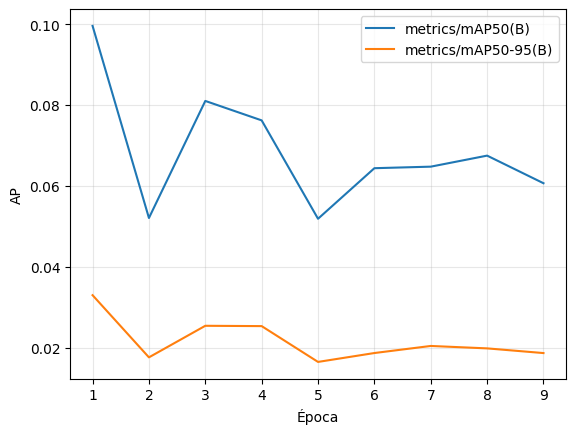

In [ ]:
if not RUTA_BEST.exists():
  raise FileNotFoundError("Aún no existe best_ap50.pt en Drive")
resultado = json.loads(RUTA_ESTADO.read_text())
print("Mejor época:", resultado["mejor_epoca"], "| AP50:", round(resultado["mejor_ap50"], 4), "| Métricas:", resultado.get("mejores_metricas", {}))
print("Checkpoints:", RUTA_LAST, RUTA_BEST)
hist = DIR_FINAL / "historial.csv"
if hist.exists():
    df = pd.read_csv(hist)
    df.columns = df.columns.str.strip()
    for nombre in ("metrics/mAP50(B)", "metrics/mAP50-95(B)"): plt.plot(df["epoch"], df[nombre], label=nombre)
    plt.xlabel("Época"); plt.ylabel("AP"); plt.grid(alpha=0.3); plt.legend(); plt.show()


In [ ]:
# detener ejecucion
from google.colab import drive, runtime

if estado.get("finalizado") and RUTA_LAST.is_file() and RUTA_BEST.is_file():
    print("Entrenamiento finalizado. Checkpoints guardados en Drive.")
    drive.flush_and_unmount()
    runtime.unassign()
else:
    print("No se confirmó la finalización. El entorno permanece activo.")

Entrenamiento finalizado. Checkpoints guardados en Drive.
